# Interpretasi Model

Notebook ini menjawab pertanyaan: **fitur apa yang paling banyak dipakai model untuk membedakan pelanggan churn dan tidak churn, dan ke arah mana?**

**Model:** XGBoost, parameter default, tanpa pembobotan, 12 fitur (keputusan 31). **Data:** hanya data latih, dan data uji tidak dipakai (keputusan 34 dan catatan keputusan 24).

Ada dua cara yang dipakai, karena keduanya menjawab hal yang sedikit berbeda:

| Cara | Pertanyaan yang dijawab | Cara kerja sederhananya |
|---|---|---|
| **Permutation importance** | Seberapa besar model **bergantung** pada fitur ini? | Isi satu fitur diacak sehingga informasinya rusak, lalu diukur seberapa turun PR-AUC. Makin besar penurunannya, makin model bergantung pada fitur itu |
| **SHAP** | Seberapa besar fitur ini **menggeser skor** tiap pelanggan, dan ke arah mana? | Skor tiap pelanggan dipecah menjadi sumbangan tiap fitur. Sumbangan positif menaikkan skor risiko, dan sumbangan negatif menurunkannya |

SHAP dihitung dengan fungsi bawaan XGBoost (`pred_contribs=True`). Library `shap` 0.49.1 sempat dicoba, tetapi gagal membaca model XGBoost 3.2.0, jadi tidak dipakai (keputusan 34).

**Penting:** kedua cara menjelaskan **cara model bekerja**, bukan **penyebab churn**. Jika sebuah fitur penting, artinya model banyak memakainya, bukan berarti fitur itu menyebabkan pelanggan berhenti.

**Keterbatasan:** Analisis mengikuti dokumentasi UCI yang menyatakan tiap baris mewakili satu pelanggan. Audit menemukan pola berulang per 50 baris, sehingga independensi antarbaris tidak terjamin dan skor model bisa terlalu optimistis.

## 1. Persiapan

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import average_precision_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedGroupKFold, train_test_split
from xgboost import XGBClassifier

SEED = 180915
N_SPLITS = 5
N_REPEATS = 10
N_PERMUTATIONS = 5

USAGE_GROUP = ['Seconds_of_Use', 'Frequency_of_use', 'Frequency_of_SMS', 'Distinct_Called_Numbers', 'Customer_Value']
GROUP_NAME = 'Kelompok pemakaian (5 kolom)'

# Path relatif terhadap root project
ROOT = Path.cwd().parent if Path.cwd().name == 'program' else Path.cwd()

In [2]:
df = pd.read_csv(ROOT / 'dataset_clean' / 'customer_churn_clean.csv')
groups = pd.read_csv(ROOT / 'dataset_clean' / 'validation_groups.csv')
assert len(groups) == len(df)

TARGET = 'Churn'
FEATURES = [col for col in df.columns if col not in (TARGET, 'Age_Binning')]
assert TARGET not in FEATURES and 'audit_group' not in FEATURES and 'Age_Binning' not in FEATURES
assert len(FEATURES) == 12 and set(USAGE_GROUP) <= set(FEATURES)

# Pembagian yang sama dengan notebook sebelumnya. Data uji tidak dipakai di notebook ini
train_idx, _ = train_test_split(df.index, test_size=0.2, stratify=df[TARGET], random_state=SEED)
train = df.loc[train_idx].reset_index(drop=True)
X, y = train[FEATURES], train[TARGET].to_numpy()
# Kelompok audit hanya untuk cek internal di bagian 6, bukan fitur model
audit_group = groups.loc[train_idx, 'audit_group'].to_numpy()
assert len(train) == 2280 and y.sum() == 357

print(f'Data latih: {len(train):,} baris, {y.sum():,} churn, {len(FEATURES)} fitur')

Data latih: 2,280 baris, 357 churn, 12 fitur


## 2. Permutation importance

Untuk setiap fold, model dilatih pada sebagian data latih, lalu dinilai pada fold validasi. Kemudian isi satu fitur di fold validasi diacak 5 kali, dan dicatat rata-rata turunnya PR-AUC. Hasilnya dirata-ratakan per fold, lalu per ulangan, sama seperti cara skor dihitung di Fase 2 (keputusan 22).

**Fitur yang saling mirip.** Lima fitur pemakaian saling berkorelasi. Kalau satu diacak, model masih bisa memakai yang lain, sehingga kepentingannya terlihat kecil. Karena itu, kelima fitur juga diacak **bersama** dan dilaporkan sebagai satu kelompok.

In [3]:
def new_model():
    return XGBClassifier(random_state=SEED, eval_metric='logloss')


ITEMS = {**{feature: [feature] for feature in FEATURES}, GROUP_NAME: USAGE_GROUP}


def permutation_drops(model, X_val, y_val, rng):
    base = average_precision_score(y_val, model.predict_proba(X_val)[:, 1])
    drops = {}
    for name, columns in ITEMS.items():
        values = []
        for _ in range(N_PERMUTATIONS):
            shuffled = X_val.copy()
            # Baris diacak bersama untuk semua kolom dalam satu item
            shuffled[columns] = X_val[columns].to_numpy()[rng.permutation(len(X_val))]
            values.append(base - average_precision_score(y_val, model.predict_proba(shuffled)[:, 1]))
        drops[name] = np.mean(values)
    return base, drops


def run_permutation(repeats, rng):
    # repeats: daftar ulangan, tiap ulangan berisi daftar (fit_idx, val_idx)
    per_repeat, bases = [], []
    for splits in repeats:
        fold_drops, fold_bases = [], []
        for fit_idx, val_idx in splits:
            # Fold tanpa churn dilewati, karena PR-AUC tidak bisa dihitung
            if y[val_idx].max() == 0:
                continue
            model = new_model().fit(X.iloc[fit_idx], y[fit_idx])
            base, drops = permutation_drops(model, X.iloc[val_idx], y[val_idx], rng)
            fold_drops.append(drops)
            fold_bases.append(base)
        per_repeat.append(pd.DataFrame(fold_drops).mean())
        bases.append(np.mean(fold_bases))
    return pd.DataFrame(per_repeat), bases


splits = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED + 1).split(X, y))
random_repeats = [splits[i:i + N_SPLITS] for i in range(0, len(splits), N_SPLITS)]
perm_random, random_bases = run_permutation(random_repeats, np.random.default_rng(SEED))

print(f'PR-AUC dasar per fold, rata-rata 10 ulangan: {np.mean(random_bases):.3f} '
      f'({min(random_bases):.3f} sampai {max(random_bases):.3f})')


def summarize(table):
    return pd.DataFrame({
        'Turun PR-AUC': table.mean(),
        'Minimum ulangan': table.min(),
        'Maksimum ulangan': table.max(),
    }).sort_values('Turun PR-AUC', ascending=False)


perm_summary = summarize(perm_random)
assert abs(perm_summary.loc['Tariff_Plan', 'Turun PR-AUC']) < 0.005
print(perm_summary.round(3).to_string())

PR-AUC dasar per fold, rata-rata 10 ulangan: 0.934 (0.926 sampai 0.939)
                              Turun PR-AUC  Minimum ulangan  Maksimum ulangan
Kelompok pemakaian (5 kolom)         0.446            0.427             0.463
Complains                            0.224            0.208             0.239
Frequency_of_use                     0.167            0.154             0.178
Subscription_Length                  0.127            0.118             0.133
Status                               0.099            0.092             0.108
Call_Failure                         0.096            0.084             0.108
Seconds_of_Use                       0.093            0.079             0.108
Age_Group                            0.049            0.042             0.054
Distinct_Called_Numbers              0.034            0.029             0.038
Customer_Value                       0.022            0.014             0.029
Frequency_of_SMS                     0.016            0.010           

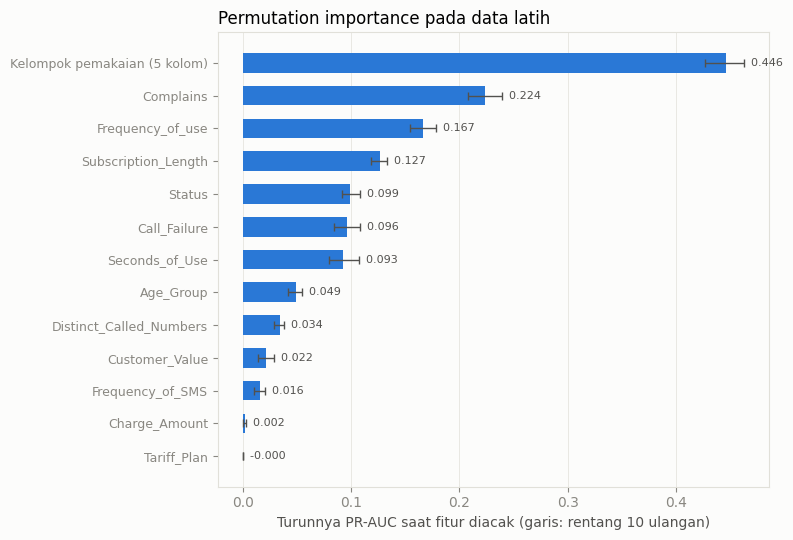

In [4]:
blue, ink_secondary, ink_muted, grid_color, surface = '#2a78d6', '#52514e', '#898781', '#e1e0d9', '#fcfcfb'


def bar_chart(summary, value_col, low_col, high_col, title, xlabel):
    ordered = summary.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 5.5), facecolor=surface)
    ax.set_facecolor(surface)
    positions = np.arange(len(ordered))
    ax.barh(positions, ordered[value_col], color=blue, height=0.6)
    if low_col:
        ax.errorbar(ordered[value_col], positions,
                    xerr=[ordered[value_col] - ordered[low_col], ordered[high_col] - ordered[value_col]],
                    fmt='none', ecolor=ink_secondary, elinewidth=1, capsize=3)
    # Label ditaruh di kanan ujung rentang supaya tidak menabrak garis rentang
    label_x = ordered[high_col] if high_col else ordered[value_col]
    for pos, value, x_pos in zip(positions, ordered[value_col], label_x):
        ax.text(max(x_pos, 0), pos, f'  {value:.3f}', va='center', fontsize=8, color=ink_secondary)
    ax.set_yticks(positions, ordered.index, fontsize=9)
    ax.set_xlabel(xlabel, color=ink_secondary)
    ax.set_title(title, loc='left', fontsize=12)
    ax.tick_params(colors=ink_muted)
    for spine in ax.spines.values():
        spine.set_color(grid_color)
    ax.grid(axis='x', color=grid_color, linewidth=0.5)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()


bar_chart(perm_summary, 'Turun PR-AUC', 'Minimum ulangan', 'Maksimum ulangan',
          'Permutation importance pada data latih',
          'Turunnya PR-AUC saat fitur diacak (garis: rentang 10 ulangan)')

**Cara membaca:** batang yang lebih panjang berarti model lebih bergantung pada fitur itu. Garis kecil di ujung batang menunjukkan rentang hasil dari 10 ulangan. Batang **kelompok pemakaian** menunjukkan apa yang terjadi jika kelima fitur pemakaian dirusak sekaligus. Nilainya jauh lebih besar daripada tiap fitur pemakaian secara sendiri-sendiri, karena saat satu diacak, fitur lain masih membawa informasi yang mirip.

## 3. SHAP

SHAP memecah skor tiap pelanggan menjadi sumbangan tiap fitur, dalam satuan log-odds. Satuan ini adalah skala internal model: angka 0 berarti tidak menggeser skor, positif menaikkan risiko, dan negatif menurunkannya.

Setiap pelanggan dijelaskan oleh model yang **tidak melihat pelanggan itu saat dilatih** (out-of-fold). Ukuran kepentingan global adalah rata-rata besar sumbangan, tanpa melihat tandanya.

                         Rata-rata |SHAP|  Minimum ulangan  Maksimum ulangan
Frequency_of_use                    1.768            1.715             1.806
Status                              1.502            1.473             1.538
Call_Failure                        1.106            1.086             1.145
Complains                           0.915            0.894             0.930
Subscription_Length                 0.881            0.864             0.911
Seconds_of_Use                      0.828            0.774             0.890
Customer_Value                      0.807            0.737             0.887
Distinct_Called_Numbers             0.429            0.406             0.444
Frequency_of_SMS                    0.358            0.332             0.398
Age_Group                           0.357            0.321             0.375
Charge_Amount                       0.202            0.165             0.223
Tariff_Plan                         0.000            0.000             0.001

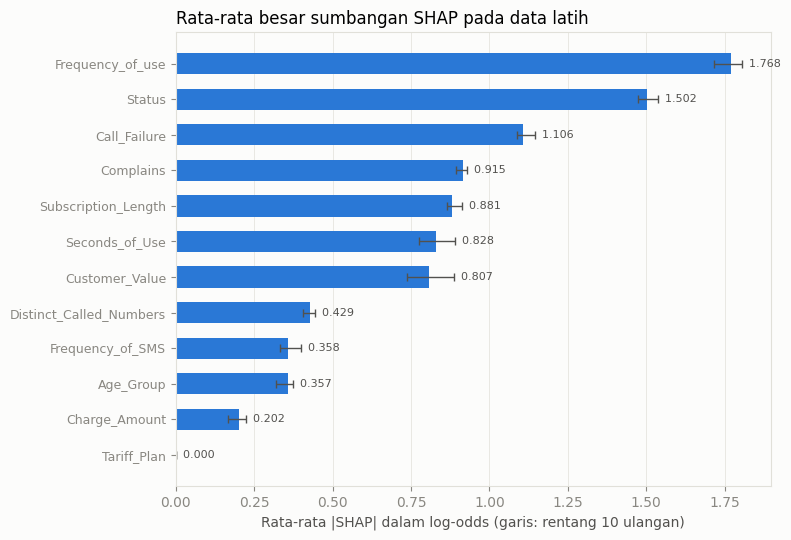

In [5]:
oof_shap = np.zeros((N_REPEATS, len(train), len(FEATURES)))
for repeat, splits in enumerate(random_repeats):
    for fit_idx, val_idx in splits:
        model = new_model().fit(X.iloc[fit_idx], y[fit_idx])
        dval = xgb.DMatrix(X.iloc[val_idx])
        contribs = model.get_booster().predict(dval, pred_contribs=True)
        margin = model.get_booster().predict(dval, output_margin=True)
        # Jumlah sumbangan semua fitur ditambah nilai dasar harus sama dengan skor model (log-odds)
        assert np.allclose(contribs.sum(axis=1), margin, atol=1e-4)
        oof_shap[repeat, val_idx] = contribs[:, :-1]

mean_abs = np.abs(oof_shap).mean(axis=1)  # per ulangan, per fitur
shap_summary = pd.DataFrame({
    'Rata-rata |SHAP|': mean_abs.mean(axis=0),
    'Minimum ulangan': mean_abs.min(axis=0),
    'Maksimum ulangan': mean_abs.max(axis=0),
}, index=FEATURES).sort_values('Rata-rata |SHAP|', ascending=False)
print(shap_summary.round(3).to_string())
bar_chart(shap_summary, 'Rata-rata |SHAP|', 'Minimum ulangan', 'Maksimum ulangan',
          'Rata-rata besar sumbangan SHAP pada data latih',
          'Rata-rata |SHAP| dalam log-odds (garis: rentang 10 ulangan)')

**Cara membaca:** batang yang lebih panjang berarti fitur itu rata-rata menggeser skor pelanggan lebih jauh, ke arah naik atau turun. Arah geserannya dibahas di bagian 5.

## 4. Mengapa urutan kedua cara berbeda

Kedua cara bisa memberi urutan berbeda, dan itu tidak berarti salah satunya keliru:

- **SHAP** membagi skor ke fitur-fitur. Jika dua fitur membawa informasi mirip, sumbangannya terbagi ke keduanya, dan **keduanya tetap terlihat besar**.
- **Permutation** mengukur kerugian jika satu fitur hilang. Jika fitur lain bisa menggantikannya, kerugiannya kecil, sehingga fitur itu **terlihat kecil**, walaupun model sering memakainya.

Jadi fitur yang besar di SHAP tetapi kecil di permutation biasanya punya "pengganti" di antara fitur lain.

In [6]:
ranks = pd.DataFrame({
    'Urutan permutation': perm_summary.drop(index=GROUP_NAME)['Turun PR-AUC'].rank(ascending=False).astype(int),
    'Urutan SHAP': shap_summary['Rata-rata |SHAP|'].rank(ascending=False).astype(int),
    'Termasuk kelompok pemakaian': pd.Series({f: 'ya' if f in USAGE_GROUP else '' for f in FEATURES}),
}).sort_values('Urutan permutation')
rank_corr = ranks['Urutan permutation'].corr(ranks['Urutan SHAP'], method='spearman')
print(ranks.to_string())
print()
print(f'Kesamaan urutan kedua cara (korelasi Spearman): {rank_corr:.2f}')

                         Urutan permutation  Urutan SHAP Termasuk kelompok pemakaian
Complains                                 1            4                            
Frequency_of_use                          2            1                          ya
Subscription_Length                       3            5                            
Status                                    4            2                            
Call_Failure                              5            3                            
Seconds_of_Use                            6            6                          ya
Age_Group                                 7           10                            
Distinct_Called_Numbers                   8            8                          ya
Customer_Value                            9            7                          ya
Frequency_of_SMS                         10            9                          ya
Charge_Amount                            11           11         

## 5. Arah hubungan untuk 4 fitur teratas

Grafik ini memperlihatkan, untuk setiap pelanggan, nilai fitur (sumbu datar) dan sumbangan SHAP-nya (sumbu tegak). Titik di atas garis 0 berarti fitur itu menaikkan skor risiko pelanggan tersebut. Sumbangan SHAP tiap pelanggan adalah rata-rata dari 10 ulangan.

Untuk fitur dengan dua nilai (`Status` dan `Complains`), titik digeser sedikit ke samping secara acak supaya tidak bertumpuk. Pergeseran ini hanya tampilan.

**Peringatan:** arah pada fitur yang saling berkorelasi bisa menyesatkan, karena model bisa memakai satu fitur untuk "mengoreksi" fitur lain. Arah ini menjelaskan model, bukan perilaku pelanggan.

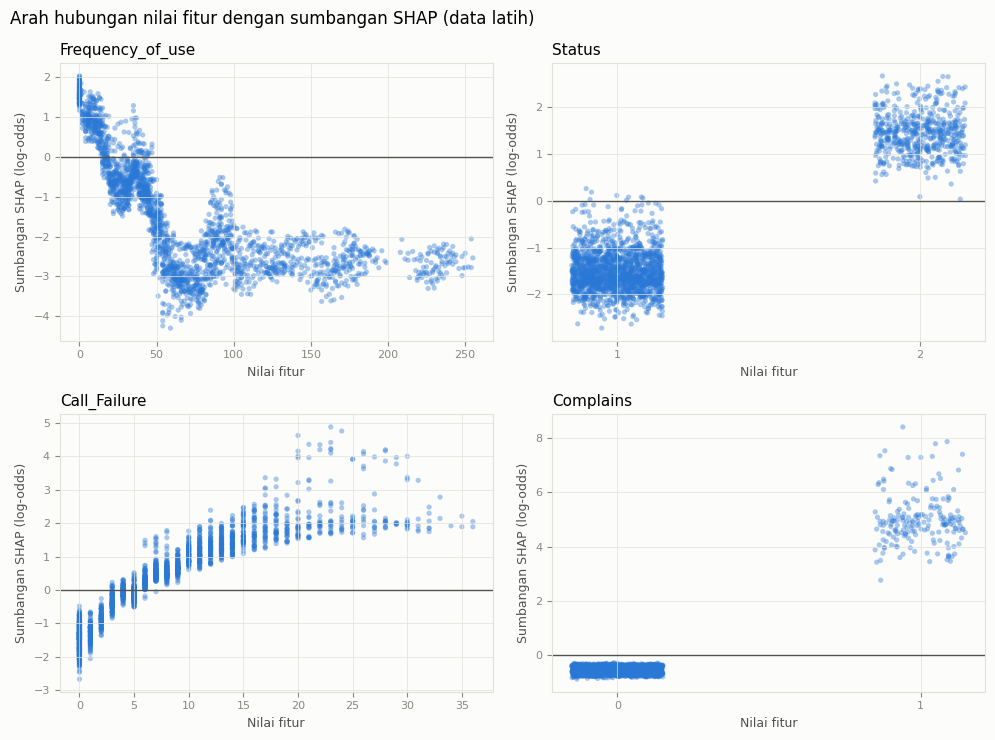

           Fitur                                                 Ringkasan arah
Frequency_of_use                         Spearman nilai fitur dengan SHAP -0.82
          Status Rata-rata sumbangan per nilai (nilai 1: -1.52, nilai 2: +1.44)
    Call_Failure                         Spearman nilai fitur dengan SHAP +0.97
       Complains Rata-rata sumbangan per nilai (nilai 0: -0.55, nilai 1: +5.00)


In [7]:
row_shap = oof_shap.mean(axis=0)
top4 = list(shap_summary.index[:4])
jitter_rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(2, 2, figsize=(10, 7.5), facecolor=surface)
for ax, feature in zip(axes.ravel(), top4):
    i = FEATURES.index(feature)
    x_values = X[feature].to_numpy().astype(float)
    if X[feature].nunique() <= 2:
        x_values = x_values + jitter_rng.uniform(-0.15, 0.15, len(x_values))
        ax.set_xticks(sorted(X[feature].unique()))
    ax.set_facecolor(surface)
    ax.scatter(x_values, row_shap[:, i], s=14, color=blue, alpha=0.4, edgecolors='none')
    ax.axhline(0, color=ink_secondary, linewidth=1)
    ax.set_title(feature, loc='left', fontsize=11)
    ax.set_xlabel('Nilai fitur', color=ink_secondary, fontsize=9)
    ax.set_ylabel('Sumbangan SHAP (log-odds)', color=ink_secondary, fontsize=9)
    ax.tick_params(colors=ink_muted, labelsize=8)
    for spine in ax.spines.values():
        spine.set_color(grid_color)
    ax.grid(color=grid_color, linewidth=0.5)
fig.suptitle('Arah hubungan nilai fitur dengan sumbangan SHAP (data latih)', x=0.01, ha='left', fontsize=12)
plt.tight_layout()
plt.show()

rows = []
for feature in top4:
    i = FEATURES.index(feature)
    if X[feature].nunique() <= 2:
        detail = ', '.join(f'nilai {v}: {row_shap[X[feature].to_numpy() == v, i].mean():+.2f}'
                           for v in sorted(X[feature].unique()))
        rows.append({'Fitur': feature, 'Ringkasan arah': f'Rata-rata sumbangan per nilai ({detail})'})
    else:
        corr = pd.Series(X[feature].to_numpy()).corr(pd.Series(row_shap[:, i]), method='spearman')
        rows.append({'Fitur': feature, 'Ringkasan arah': f'Spearman nilai fitur dengan SHAP {corr:+.2f}'})
print(pd.DataFrame(rows).to_string(index=False))

**Cara membaca:** untuk fitur angka, korelasi Spearman positif berarti nilai yang lebih tinggi cenderung menaikkan skor risiko, dan negatif berarti menurunkannya. Untuk `Status`, nilai 1 adalah aktif dan 2 non-aktif. Untuk `Complains`, nilai 0 berarti tidak ada komplain dan 1 berarti ada komplain. Semua ini adalah pola pada model dan data ini, bukan sebab churn.

## 6. Cek internal: apakah urutan fitur bertahan pada CV grup

Audit Fase 1 menemukan pola berulang per 50 baris. Di sini permutation importance dihitung ulang dengan CV grup, yaitu baris dari kelompok audit yang sama tidak boleh berada di data latih dan validasi sekaligus, sama seperti cek internal Fase 2.

Jika urutan fitur mirip, peran fitur tidak bergantung pada pola berulang. Jika berbeda jauh, sebagian peran fitur di CV acak mungkin datang dari kemiripan antarbaris dalam satu kelompok. Skor CV grup tidak dimasukkan ke README (keputusan 2).

In [8]:
group_repeats = []
for repeat in range(N_REPEATS):
    splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED + repeat)
    folds = list(splitter.split(X, y, audit_group))
    # Satu kelompok tidak boleh berada di data latih dan validasi sekaligus
    for fit_idx, val_idx in folds:
        assert not set(audit_group[fit_idx]) & set(audit_group[val_idx])
    group_repeats.append(folds)

perm_group, group_bases = run_permutation(group_repeats, np.random.default_rng(SEED))
group_summary = summarize(perm_group)

comparison = pd.DataFrame({
    'Turun PR-AUC, CV acak': perm_summary['Turun PR-AUC'],
    'Urutan, CV acak': perm_summary['Turun PR-AUC'].rank(ascending=False).astype(int),
    'Turun PR-AUC, CV grup': group_summary['Turun PR-AUC'],
    'Urutan, CV grup': group_summary['Turun PR-AUC'].rank(ascending=False).astype(int),
}).sort_values('Urutan, CV acak')
order_corr = comparison['Urutan, CV acak'].corr(comparison['Urutan, CV grup'], method='spearman')
print(f'PR-AUC dasar per fold, CV grup: {np.mean(group_bases):.3f} ({min(group_bases):.3f} sampai {max(group_bases):.3f})')
print(comparison.round(3).to_string())
print()
print(f'Kesamaan urutan CV acak dan CV grup (korelasi Spearman): {order_corr:.2f}')
shift = comparison['Urutan, CV grup'] - comparison['Urutan, CV acak']
print('Turun paling jauh di CV grup:', ', '.join(f'{f} ({comparison.loc[f, "Urutan, CV acak"]} ke {comparison.loc[f, "Urutan, CV grup"]})'
                                                for f in shift[shift >= 4].index))
print('Bertahan di 5 besar pada kedua CV:', ', '.join(
    f for f in comparison.index if comparison.loc[f, 'Urutan, CV acak'] <= 5 and comparison.loc[f, 'Urutan, CV grup'] <= 5))
print('Penurunan negatif di CV grup (mengacak fitur justru menaikkan skor):', ', '.join(
    group_summary.index[group_summary['Turun PR-AUC'] < 0]))

PR-AUC dasar per fold, CV grup: 0.474 (0.323 sampai 0.588)
                              Turun PR-AUC, CV acak  Urutan, CV acak  Turun PR-AUC, CV grup  Urutan, CV grup
Kelompok pemakaian (5 kolom)                  0.446                1                  0.104                2
Complains                                     0.224                2                  0.221                1
Frequency_of_use                              0.167                3                  0.073                3
Subscription_Length                           0.127                4                  0.006                8
Status                                        0.099                5                  0.041                4
Call_Failure                                  0.096                6                  0.035                5
Seconds_of_Use                                0.093                7                 -0.027               13
Age_Group                                     0.049                8 

**Cara membaca:** bandingkan kolom urutan. Penurunan PR-AUC pada CV grup tidak bisa dibandingkan langsung dengan CV acak, karena PR-AUC dasarnya jauh berbeda. Yang dibaca di sini adalah **urutan**, bukan besar angkanya.

- **Fitur yang bertahan di 5 besar pada kedua CV** adalah peran yang paling bisa dipercaya, karena tetap dipakai walaupun model menilai kelompok audit yang belum pernah dilihatnya.
- **Fitur yang turun jauh di CV grup** kemungkinan besar perannya di CV acak datang dari kemiripan antarbaris dalam satu kelompok audit. Contohnya `Subscription_Length`. Audit Fase 1 menemukan bahwa semua baris churn dengan lama berlangganan pendek berasal dari satu kelompok audit (temuan 6 di `PROJECT_GUIDE.md`).
- **Penurunan negatif** berarti mengacak fitur itu justru sedikit menaikkan skor pada kelompok baru. Model memakai fitur itu untuk pola yang tidak berlaku di kelompok lain.

## 7. Perbandingan dengan jurnal

| Sumber | Model dan cara | Fitur teratas yang dilaporkan |
|---|---|---|
| Damuri dkk. (2026) | XGBoost, SHAP | Frequency of Use, Status, Seconds of Use, Call Failure, Subscription Length, Complains |
| Wang dkk. (2025) | CatBoost, SHAP. `Frequency of use` dan `Customer Value` dibuang sebelum modeling karena berkorelasi tinggi | Seconds of Use, Call Failure, Frequency of SMS, Subscription Length, Status, Complains |
| Notebook ini | XGBoost, SHAP dan permutation, ditambah kelompok pemakaian dan cek CV grup | Lihat bagian 2 sampai 4 |

Urutan SHAP di sini perlu dibandingkan dengan Damuri dkk., yang memakai model dan fitur paling mirip. Perbedaan Wang dkk. sejalan dengan bagian 4: ketika `Frequency of use` dibuang, perannya cenderung pindah ke fitur pemakaian lain seperti `Seconds of Use`. Jadi urutan antarfitur pemakaian sangat bergantung pada fitur mana yang disertakan, sedangkan kelompok pemakaian secara keseluruhan tetap menjadi sinyal penting.

Jurnal hanya diperiksa lewat pencarian kata kunci dan bagian hasil, bukan dibaca penuh.

## Cara membaca hasil

**Ringkasnya:**

- Pada CV acak, model paling bergantung pada **pola pemakaian** secara keseluruhan, lalu pada **komplain**, **lama berlangganan**, **status**, dan **kegagalan panggilan**.
- Pada cek CV grup, **komplain**, **pola pemakaian**, **frekuensi panggilan**, dan **status** tetap di lima besar, dan **kegagalan panggilan** berada tepat di sekitarnya. Peran **lama berlangganan** hampir hilang, jadi peran itu kemungkinan besar datang dari pola berulang di data.
- `Tariff_Plan` dan `Charge_Amount` hampir tidak dipakai model.
- Urutan antarfitur pemakaian tidak stabil antarcara, karena fitur-fitur itu saling menggantikan.

**Keterbatasan:**

1. **Bukan sebab-akibat.** Fitur penting berarti model banyak memakainya, bukan penyebab churn.
2. **Fitur berkorelasi berbagi kepentingan.** Kepentingan satu fitur pemakaian bisa terlihat kecil karena ada penggantinya.
3. **`Status` belum jelas asalnya.** UCI tidak menjelaskan cara `Status` ditentukan (keputusan 29), jadi perannya di model perlu dibaca hati-hati.
4. **CV acak bisa menonjolkan pola berulang.** Cek CV grup di bagian 6 memberi gambaran seberapa besar pengaruhnya.
5. **SHAP dalam log-odds.** Satuan ini adalah skala internal model, bukan peluang churn.
6. **Bukan performa pada pelanggan baru.** Semua angka berasal dari data latih.